# Generate Data

This notebook uses `qim3d` to generate meshes suitable for simulation in `gVXR`.


In [1]:
from pathlib import Path

import qim3d
import trimesh

import common

In [2]:
seed = 42

shape = (128, 128, 128)
num_threads = 18
thread_thickness = 20
thread_spacing = 0.85
noise_scale = 0.1

vol, labels = qim3d.generate.rope(
    shape=shape,
    num_threads=num_threads,
    noise_scale=noise_scale,
    thread_thickness=thread_thickness,
    thread_spacing=thread_spacing,
    seed=seed,
    return_labels=True,
)

In [3]:
labels.max()

np.uint8(18)

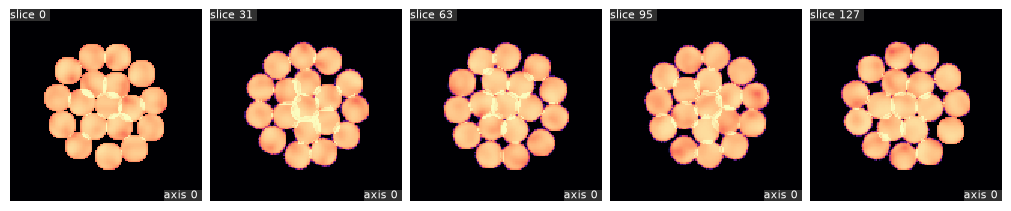

In [4]:
qim3d.viz.slices_grid(vol, n_slices=5)


In [5]:
qim3d.viz.planes(vol, colormap="plasma")

FigureWidget({
    'data': [{'cmax': 255,
              'cmin': np.uint8(0),
              'colorscale': [[0.0, 'rgb(13, 8, 135)'], [0.00392156862745098,
                             'rgb(16, 7, 136)'], [0.00784313725490196, 'rgb(19, 7,
                             137)'], ..., [0.9921568627450981, 'rgb(241, 245,
                             37)'], [0.996078431372549, 'rgb(240, 247, 36)'], [1.0,
                             'rgb(240, 249, 33)']],
              'lighting': {'ambient': 1, 'diffuse': 0, 'fresnel': 0, 'roughness': 1, 'specular': 0},
              'name': 'Z',
              'opacity': 1.0,
              'showlegend': False,
              'showscale': False,
              'surfacecolor': array([[0, 0, 0, ..., 0, 0, 0],
                                     [0, 0, 0, ..., 0, 0, 0],
                                     [0, 0, 0, ..., 0, 0, 0],
                                     ...,
                                     [0, 0, 0, ..., 0, 0, 0],
                                

In [6]:
qim3d.viz.volumetric(vol)

Output()

In [7]:
data_dir = common.data_dir
data_dir.mkdir(exist_ok=True, parents=True)
print(f"{data_dir=}")

qim3d.io.save(data_dir / "input_volume", vol, basename="slice", sliced_dim=0)
qim3d.io.save(data_dir / "input_labels", labels, basename="slice", sliced_dim=0)

qim3d.io.save(data_dir / "input_volume.tif", vol, replace=True)
qim3d.io.save(data_dir / "input_labels.tif", labels, replace=True)


data_dir=PosixPath('/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data')


In [8]:
mesh = qim3d.mesh.from_volume(vol, backend="pygel", return_pygel3d=True)


In [9]:
rope_dir = data_dir / "rope"
rope_dir.mkdir(exist_ok=True)

for label in range(1, labels.max() + 1):
    fibre = (labels == label).astype("uint8")
    qim3d.io.save(rope_dir / f"input_fibre_{label}.tif", fibre, replace=True)

    # Mesh the fibre
    meshed_fibre = qim3d.mesh.from_volume(fibre, backend="pygel", return_pygel3d=True)

    # Save as STL
    verts = meshed_fibre.positions()
    faces = [
        list(meshed_fibre.circulate_face(f, mode="v")) for f in meshed_fibre.faces()
    ]
    trimesh.Trimesh(vertices=verts, faces=faces, process=False).export(
        rope_dir / f"input_fibre_{label}.stl"
    )
